## Etape 1 : Audit et nettoyage

In [3]:
import pandas as pd

df = pd.read_csv("textes_films_horreur_comedie.csv")

In [4]:
print(f"{df.cible.sum()} cibles 1 (horreur), {len(df.cible) - df.cible.sum()} cibles 0 (comédies)")

1200 cibles 1 (horreur), 1200 cibles 0 (comédies)


In [5]:
# suppression des espaces intempestifs
import re
df["titre"] = df["titre"].apply(lambda str: re.sub(r"  +"," ",str.strip()))
df["resume"] = df["resume"].apply(lambda str: re.sub(r"  +"," ",str.strip()))

In [6]:
# gestion des doublons
print(len(df.value_counts()[df.value_counts() > 1]),"films en doublon")
df.drop_duplicates(inplace=True)

51 films en doublon


In [7]:
print(f"{df.cible.sum()} cibles 1 (horreur), {len(df.cible) - df.cible.sum()} cibles 0 (comédies)")

1151 cibles 1 (horreur), 1195 cibles 0 (comédies)


54 lignes en doublon ont donc été supprimées (3 lignes étaient même triplées).

In [8]:
print(len(df.value_counts("titre")[df.value_counts("titre") > 1]),"titres de films en doublon")

56 titres de films en doublon


In [9]:
df[df["titre"]=="Dracula"]

,titre,resume,cible
1126,Dracula,This version of Dracula is closely based on Br...,1
1509,Dracula,After a harrowing ride through the Carpathian ...,1
2086,Dracula,"When a ship is wrecked off Whitby, the only su...",1


On suppose donc qu'il s'agit de films différents, même s'ils ont le même titre.

## Etape 2 : Découpage du jeu de données
Séparer les textes en trois parties : 60 % apprentissage, 20% test, 20% production

In [10]:
from sklearn.model_selection import train_test_split
train, testProd, y_train, y_testProd = train_test_split(df["resume"], df["cible"], test_size=0.4, stratify=df["cible"], random_state=42)
test, prod, y_test, y_prod = train_test_split(testProd, y_testProd, test_size=0.5, stratify=y_testProd, random_state=42)
print("Répartition train / test / prod :")
print(f"* comédies : {len(y_train[y_train==0])} / {len(y_test[y_test==0])} / {len(y_prod[y_prod==0])}")
print(f"* horreurs : {len(y_train[y_train==1])} / {len(y_test[y_test==1])} / {len(y_prod[y_prod==1])}")

Répartition train / test / prod :
* comédies : 717 / 239 / 239
* horreurs : 690 / 230 / 231


## Etape 3 : Vectorisation du texte TF-IDF

In [11]:
from sklearn.feature_extraction.text import TfidfVectorizer
vectorizer = TfidfVectorizer(stop_words="english", max_features=15000)
X_train = vectorizer.fit_transform(train.apply(lambda str:str.lower()))
X_test = vectorizer.transform(test.apply(lambda str:str.lower()))
X_prod = vectorizer.transform(prod.apply(lambda str:str.lower()))

In [12]:
print("Taille du vocabulaire :",X_train.shape[1])

Taille du vocabulaire : 14599


## Etape 4 : Comparaison de 3 modèles

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import f1_score
from keras.utils import set_random_seed
from keras import Sequential
from keras.layers import Input, Dense, Dropout, GlobalMaxPooling1D, Conv1D, Embedding
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping
import numpy as np

# on réserve une partie du training pour la validation
X_tr, X_vld, y_tr, y_vld = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=42)

# modele Logistic Regression :
modele = LogisticRegression(
    C=2,
    max_iter=2000
).fit(X_tr, y_tr)
f1_LogReg = 0
meilleur_seuil = 0
y_proba = modele.predict_proba(X_vld)[:, 1]
for seuil in np.arange(0.40, 0.61, 0.01):
    y_pred = (y_proba >= seuil).astype(int)
    f1 = f1_score(np.array(y_vld).ravel(), y_pred)
    if f1 > f1_LogReg:
        f1_LogReg = f1
        meilleur_seuil = seuil
# modele Bayes naïf :
f1_Bayes = 0 
best_alpha = 0
for alpha in [0.01, 0.1, 0.5, 1, 2, 5]:
    modele = MultinomialNB(alpha=alpha)
    modele.fit(X_tr, y_tr)
    y_pred = modele.predict(X_vld)
    f1 = f1_score(y_vld, y_pred)
    if f1 > f1_Bayes:
        f1_Bayes = f1
        best_alpha = alpha
# réseau simple :
def reseauEntraine(X_tr, y_tr, X_vld, y_vld, neurones=32, couches=1, dropout=0.2, lr=1e-3, batch=32, seed=42):
    set_random_seed(seed)
    m = Sequential([Input(shape=(X_tr.shape[1],))])
    for _ in range(couches):
        m.add(Dense(neurones, activation="relu"))
        if dropout:
            m.add(Dropout(dropout))
    m.add(Dense(1, activation="sigmoid"))
    m.compile(optimizer=Adam(lr), loss="binary_crossentropy", metrics=["accuracy"])
    if X_vld is not None:
        m.fit(X_tr, y_tr, validation_data=(X_vld, y_vld), epochs=100, batch_size=batch, callbacks=[EarlyStopping(patience=5, restore_best_weights=True)], verbose=0)
    else:
        m.fit(X_tr, y_tr, epochs=30, batch_size=batch, verbose=0)
    return m
f1_reseau = 0
nb = 0
for seed in range(5):
    modele = reseauEntraine(X_tr, y_tr, X_vld, y_vld, seed=seed)
    y_pred = modele.predict(X_vld)
    f1_reseau += f1_score(y_vld, (y_pred.ravel() >= 0.5).astype(int))
    nb += 1
f1_reseau /= nb
# bilan
print(f"Modèle Logistic Regression : {f1_LogReg} meilleur_seuil : {meilleur_seuil}, Modèle Bayes naïf : {f1_Bayes}, best_alpha : {best_alpha}, Réseau : {f1_reseau}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step 
Modèle Logistic Regression : 0.8639455782312925 meilleur_seuil : 0.44000000000000006, Modèle Bayes naïf : 0.8611111111111112, best_alpha : 0.5, Réseau : 0.840672916391564


## Etape 5 : Optimisation avec KerasTuner

In [14]:
import keras_tuner as kt
def construire_hp(hp):
    m = Sequential([Input(shape=(14599,))])
    for _ in range(hp.Int("couches", 1, 3)):
        m.add(Dense(hp.Choice("neurones", [16, 32, 64, 128]), activation="relu"))
        m.add(Dropout(hp.Choice("dropout", [0.0, 0.1, 0.2, 0.3, 0.5])))
    m.add(Dense(1, activation="sigmoid"))
    m.compile(optimizer=Adam(hp.Choice("lr", [1e-3, 3e-3, 1e-2])), loss="binary_crossentropy", metrics=["accuracy"])
    return m
tuner = kt.RandomSearch(construire_hp, objective="val_accuracy", max_trials=20, seed=0, directory="kt_tp6", project_name="digits", overwrite=True)
tuner.search(X_tr, y_tr, validation_data=(X_vld, y_vld), epochs=30, batch_size=32,
                callbacks=[EarlyStopping(patience=5, restore_best_weights=True)], verbose=0)
print("Meilleurs hyperparamètres trouvés par Keras Tuner :", tuner.get_best_hyperparameters(1)[0].values)



Meilleurs hyperparamètres trouvés par Keras Tuner : {'couches': 1, 'neurones': 64, 'dropout': 0.1, 'lr': 0.001}


In [15]:
modele = reseauEntraine(X_tr, y_tr, X_vld, y_vld, couches=1, neurones=64, dropout=0.1, lr=0.001, seed=1)
y_pred = modele.predict(X_vld)
f1_score(y_vld, (y_pred.ravel() >= 0.5).astype(int))


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


0.835820895522388

## Etape 6 : Optimisation avec Optuna

In [16]:
def construire_modele(trial):
    nb_couches = trial.suggest_int("couches", 1, 3)
    neurones = trial.suggest_categorical("neurones", [16, 32, 64, 128])
    dropout = trial.suggest_categorical("dropout", [0.0, 0.1, 0.2, 0.3, 0.5])
    lr = trial.suggest_categorical("lr", [1e-3, 3e-3, 1e-2])
    m = Sequential([Input(shape=(14599,))])
    for _ in range(nb_couches):
        m.add(Dense(neurones, activation="relu"))
        m.add(Dropout(dropout))
    m.add(Dense(1, activation="sigmoid"))
    m.compile(
        optimizer=Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )
    return m

def objective(trial):
    model = construire_modele(trial)
    model.fit(
        X_tr,
        y_tr,
        validation_data=(X_vld, y_vld),
        epochs=20,
        batch_size=32,
        verbose=0
    )
    y_proba = model.predict(X_vld, verbose=0).ravel()
    y_pred = (y_proba >= 0.5).astype(int)
    return f1_score(y_vld, y_pred)

import optuna

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=20)

print("Meilleur F1 :", study.best_value)
print("Meilleurs paramètres :", study.best_params)

c:\Users\Utilisateur\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-23 17:11:10,385] A new study created in memory with name: no-name-de2f0956-a745-4afb-9853-86b9e548c201
[I 2026-10-23 17:11:16,599] Trial 0 finished with value: 0.8301886792452831 and parameters: {'couches': 2, 'neurones': 16, 'dropout': 0.0, 'lr': 0.001}. Best is trial 0 with value: 0.8301886792452831.
[I 2026-10-23 17:11:22,862] Trial 1 finished with value: 0.8174603174603174 and parameters: {'couches': 2, 'neurones': 16, 'dropout': 0.3, 'lr': 0.01}. Best is trial 0 with value: 0.8301886792452831.
[I 2026-10-23 17:11:34,477] Trial 2 finished with value: 0.8467153284671532 and parameters: {'couches': 1, 'neurones': 64, 'dropout': 0.2, 'lr': 0.01}. Best is trial 2 with value: 0.8467153284671532.
[

Meilleur F1 : 0.8530465949820788
Meilleurs paramètres : {'couches': 1, 'neurones': 128, 'dropout': 0.5, 'lr': 0.01}


## Etape 7 : Choix des hyperparamètres

In [17]:
f1_reseau = 0
nb = 0
for seed in range(5):
    modele = reseauEntraine(X_train, y_train, None, None, couches=3, neurones=64, dropout=0.1, lr=0.003, seed=seed)
    y_pred = modele.predict(X_test)
    f1_reseau += f1_score(y_test, (y_pred.ravel() >= 0.5).astype(int))
    nb += 1
f1_reseau /= nb
print(f1_reseau)

15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
0.853975832205865


In [18]:
p = f1_reseau
n = X_test.shape[0]
bruit =  1.96 * np.sqrt(p*(1-p)/n)
print(bruit)                           

0.03195985571613283


L'optimisation a permis d'être à 85% avec les données de test, le F1 initial étant à 84% (uniquement avec les données du training). On reste dans le bruit de 3%.

## Etape 8 : Sauvegarde

In [17]:
from pathlib import Path

MODEL_DIR = Path("model")
MODEL_DIR.mkdir(exist_ok=True)

modele.save(MODEL_DIR / "modele.keras")

import joblib

joblib.dump(vectorizer, MODEL_DIR / "vectorizer.joblib")

import json
import sklearn
import tensorflow as tf
import keras
import numpy as np

metrics = {
    "version": "1.0",
    "f1_test": float(f1_reseau),
    "taille_test": len(y_test),
    "versions": {
        "python": __import__("sys").version,
        "numpy": np.__version__,
        "scikit-learn": sklearn.__version__,
        "tensorflow": tf.__version__,
        "keras": keras.__version__
    }
}
with open(MODEL_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=4)

echantillon = df.loc[test.index, ["resume", "cible"]].sample(
    n=20,
    random_state=42
)

echantillon.to_csv(
    MODEL_DIR / "echantillon_reference.csv",
    index=False,
    encoding="utf-8"
)

## Complément : définition d'une zone d'incertitude

On cherche à identifier une zone où un texte quelconque ne pourrait pas raisonnablement être qualifié de horreur ou comédie.

In [19]:
probas = modele.predict(X_test, verbose=0).ravel()
y = np.asarray(y_test)

for marge in np.arange(0, 0.46, 0.05):

    seuil_0 = 0.5 - marge
    seuil_1 = 0.5 + marge

    acceptes = (probas < seuil_0) | (probas > seuil_1)

    couverture = acceptes.mean()

    predictions = (probas[acceptes] >= 0.5).astype(int)

    f1 = f1_score(y[acceptes], predictions)

    print(
        f"{seuil_0:.2f} / {seuil_1:.2f} : "
        f"couverture={couverture:.1%}, "
        f"F1={f1:.3f}"
    )

0.50 / 0.50 : couverture=100.0%, F1=0.849
0.45 / 0.55 : couverture=99.6%, F1=0.852
0.40 / 0.60 : couverture=97.9%, F1=0.857
0.35 / 0.65 : couverture=97.2%, F1=0.860
0.30 / 0.70 : couverture=96.4%, F1=0.861
0.25 / 0.75 : couverture=95.9%, F1=0.863
0.20 / 0.80 : couverture=95.3%, F1=0.864
0.15 / 0.85 : couverture=94.7%, F1=0.867
0.10 / 0.90 : couverture=93.4%, F1=0.874
0.05 / 0.95 : couverture=90.4%, F1=0.873


Si l'on regarde l'optimum de F1, une zone d'incertitude entre 10% et 90% est la plus indiquée.

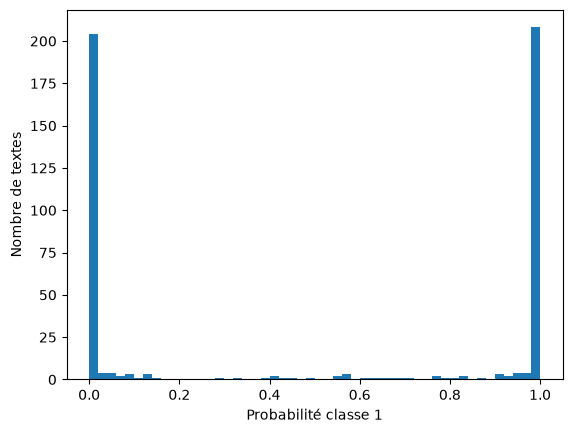

In [20]:
import matplotlib.pyplot as plt

plt.hist(probas, bins=50)
plt.xlabel("Probabilité classe 1")
plt.ylabel("Nombre de textes")
plt.show()